# Détection de SMS frauduleux (Spam/Smishing) en français
*Projet Fouille de données textuelles — M2 MAS (SDD), Université Rennes 2*

## Étape 1 — Chargement et exploration des données

On combine **deux jeux de données** de Hugging Face, complémentaires :

| Fichier | Source | Contenu |
|---|---|---|
| `data/sms_brut.csv` | `Kinoux/french-spam-ham-detection-free-2k` | 1 000 messages rédigés en français. Les ham sont surtout des **avis de clients**, les spams des publicités et des arnaques |
| `data/sms_brut_2.csv` | `dbarbedillo/SMS_Spam_Multilingual_Collection_Dataset` | La *SMS Spam Collection* (UCI) : 5 572 **vrais SMS** britanniques, ici dans leur **traduction française automatique** (colonne `text_fr`) |

**Pourquoi deux jeux ?** Avec Kinoux seul, le modèle apprenait surtout à distinguer *un avis* d'*une publicité*, car ses ham ne ressemblent pas à des SMS personnels. Le second jeu apporte de vrais échanges entre particuliers (« tu viens ce soir ? ») et des spams SMS typiques (concours, numéros surtaxés).

Les deux fichiers sont produits par le script `telecharger_donnees.py` (à lancer une seule fois) et sont fournis avec le projet.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_colwidth', 200)

In [2]:
# Chargement des deux fichiers. On ajoute une colonne 'source' pour savoir d'où vient chaque message :
# elle sert à l'exploration et à l'évaluation, mais n'est PAS donnée au modèle.
kinoux = pd.read_csv('data/sms_brut.csv', encoding='utf-8').assign(source='Kinoux')
collection = pd.read_csv('data/sms_brut_2.csv', encoding='utf-8').assign(source='SMS Collection')

print('Kinoux         :', kinoux.shape)
print('SMS Collection :', collection.shape)

df = pd.concat([kinoux, collection], ignore_index=True)
df.sample(8, random_state=0)

Kinoux         : (1000, 3)
SMS Collection : (5572, 3)


,text,label,source
6175,Raji..pls me font une faveur. Pls transmettre mes vœux d'anniversaire à Nimya. Pls. Aujourd'hui est son anniversaire.,ham,SMS Collection
6085,Désolé d'avoir raté votre appel.,ham,SMS Collection
5357,Je devrais vous envoyer mon numéro de compte.,ham,SMS Collection
4472,Le cœur est vide sans amour.. Le mental est vide sans sagesse.. Yeux r vides sans rêves &amp; La vie est vide sans frnds.. Donc Alwys Soyez In Touch. Bonne nuit &amp; rêves doux,ham,SMS Collection
4426,"C'est vrai, c'est plus facile avec elle ici.",ham,SMS Collection
5646,Vous comptez venir chenni?,ham,SMS Collection
5453,"Je t'ai dit que tout allait s'arrêter, ne la laisse pas se déshydrater.",ham,SMS Collection
495,"Jamais aussi déçu par une assurance, perte totale de confiance.",ham,Kinoux


In [3]:
# Qualité des données : valeurs manquantes et doublons
print('Valeurs manquantes :', df.isna().sum().to_dict())
print('Doublons par source :', df[df['text'].duplicated()].groupby('source').size().to_dict())

# Un même texte a-t-il parfois deux étiquettes différentes ?
print('Textes en double avec des étiquettes contradictoires :',
      (df.groupby('text')['label'].nunique() > 1).sum())

# On supprime les doublons : un message répété serait sinon à la fois dans l'apprentissage et
# dans le test, ce qui gonflerait artificiellement les scores.
df = df.drop_duplicates('text').reset_index(drop=True)
print('\nAprès suppression des doublons :', df.shape)

Valeurs manquantes : {'text': 0, 'label': 0, 'source': 0}
Doublons par source : {'SMS Collection': 438}
Textes en double avec des étiquettes contradictoires : 0

Après suppression des doublons : (6134, 3)


In [4]:
# Répartition des classes, par source et au total
repartition = pd.crosstab(df['source'], df['label'], margins=True, margins_name='Total')
repartition['% spam'] = (100 * repartition['spam'] / repartition['Total']).round(1)
repartition

label,ham,spam,Total,% spam
source,,,,
Kinoux,500,500,1000,50.0
SMS Collection,4494,640,5134,12.5
Total,4994,1140,6134,18.6


nb_caracteres  nb_mots
source         label                        
Kinoux         ham            128.0     20.3
               spam           131.0     19.0
SMS Collection ham             77.0     13.9
               spam           156.9     24.9

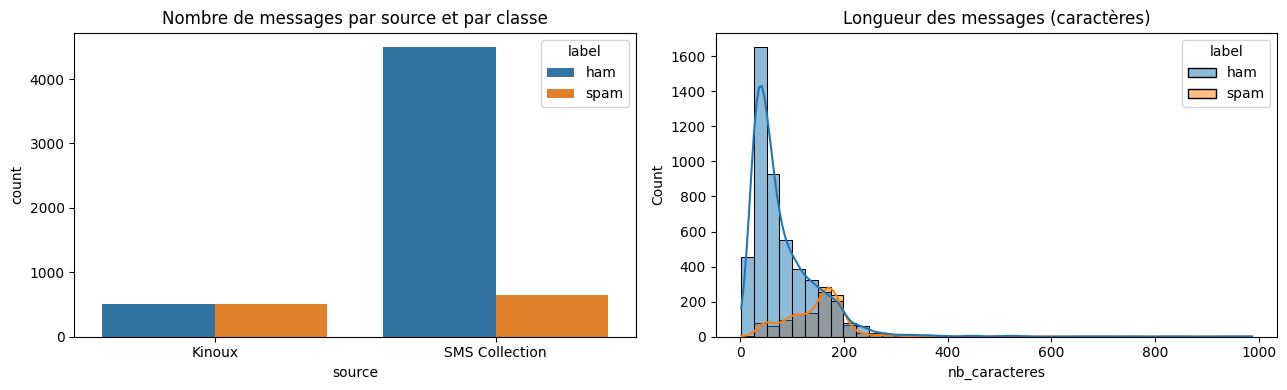

In [5]:
# Longueur des messages par classe et par source
df['nb_caracteres'] = df['text'].str.len()
df['nb_mots'] = df['text'].str.split().str.len()
display(df.groupby(['source', 'label'])[['nb_caracteres', 'nb_mots']].mean().round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x='source', hue='label', ax=axes[0])
axes[0].set_title('Nombre de messages par source et par classe')
sns.histplot(data=df, x='nb_caracteres', hue='label', bins=40, kde=True, ax=axes[1])
axes[1].set_title('Longueur des messages (caractères)')
plt.tight_layout()
plt.show()

In [6]:
# Entités à masquer à l'étape 2 : URL, montants, numéros longs (téléphone, codes SMS)
motifs = {
    'URL': r'https?://|www\.|\.co\.uk|\.com\b',
    'Montant (€, £, $)': r'[€£$]|\beuros?\b|\blivres?\b',
    'Nombre de 5+ chiffres': r'\d{5,}',
    'Markdown (**)': r'\*\*',
}
pd.DataFrame({nom: df.groupby(['source', 'label'])['text'].apply(lambda s: s.str.contains(m, case=False).sum())
              for nom, m in motifs.items()})

URL  Montant (€, £, $)  Nombre de 5+ chiffres  \
source         label                                                  
Kinoux         ham      0                  0                      0   
               spam    24                 32                      0   
SMS Collection ham     11                 32                      3   
               spam   113                230                    485   

                      Markdown (**)  
source         label                 
Kinoux         ham                0  
               spam              25  
SMS Collection ham                0  
               spam               7

In [7]:
# Quelques exemples de chaque source et de chaque classe
for (src, lab), groupe in df.groupby(['source', 'label']):
    print(f'--- {src} / {lab.upper()} ---')
    for t in groupe['text'].sample(4, random_state=42):
        print('•', t)
    print()

--- Kinoux / HAM ---
• J'ai commandé ce site web et c'est un vrai désastre. Le design est laid, plein de bugs et ça charge à une vitesse d'escargot. Pas du tout ce que j'avais demandé!
• J'ai commandé ce produit il y a plus d'une semaine et toujours rien! Le suivi de colis ne donne aucune information. C'est très frustrant et cela affecte sérieusement ma confiance en cette entreprise.
• Paiement bloqué, super frustré! Pas possible d'acheter.
• Ce logiciel de gestion réseau est incroyable ! Il simplifie la surveillance et la maintenance, tout en offrant des fonctionnalités avancées.

--- Kinoux / SPAM ---
• Gagnez des likes à vie en partageant vos informations bancaires, action limitée ! Cliquez vite avant que ce ne soit trop tard.
• Boostez votre visibilité immédiate sur les moteurs de recherche ! Nos solutions de financement immobilier vous assurent la première place. Contactez-nous pour des résultats rapides et durables.
• Chère cliente, votre compte est bloqué! Vérifiez vos informati

### Constats et conséquences pour la suite

| Constat | Conséquence |
|---|---|
| Les deux jeux sont **très différents** : Kinoux est équilibré (50 % de spams), SMS Collection ne contient qu'environ 12 % de spams | Le corpus combiné est **déséquilibré** (environ 1 spam pour 4 ham). L'*accuracy* devient trompeuse : un modèle qui répond toujours « ham » aurait déjà plus de 80 % de bonnes réponses. On évalue donc avec le **F1, la précision et le rappel de la classe spam**, et on compare deux façons de gérer le déséquilibre (`class_weight` et SMOTE) |
| SMS Collection contient des **doublons** (messages publicitaires envoyés plusieurs fois) | Supprimés, pour qu'un même message ne soit pas à la fois dans l'apprentissage et dans le test |
| Les spams de SMS Collection contiennent des **livres sterling (£)**, des **numéros surtaxés** britanniques et des sites en **.co.uk** | Les expressions régulières de l'étape 2 sont étendues à ces formats |
| La traduction est **automatique** et garde des abréviations anglaises (*u*, *2*, *4*, *txt*) | On les conserve : ce sont des marques réelles de l'écriture SMS |
| Le **markdown** (`**gras**`) n'apparaît que dans des spams | Supprimé : c'est une trace de génération du corpus, pas un indice d'arnaque |
| La proportion de spams **dépend de la source** | Le découpage apprentissage / test est **stratifié sur la classe et la source**, et les résultats sont aussi donnés **par source** |

## Étape 2 — Nettoyage et prétraitements linguistiques

### 2.A Masquage des entités par expressions régulières
**Pourquoi ?** Un modèle peut apprendre par cœur des détails, comme un nom de domaine (`bit.ly`) ou un montant précis (`£1000`), au lieu de la *structure* de l'arnaque (« gagnez **un montant** en appelant **un numéro** »). On remplace donc ces entités par des balises génériques :

| Balise | Exemples dans le corpus |
|---|---|
| `<URL>` | `https://bit.ly/2KXy9ZQ`, `www.textcomp.com`, `alto18.co.uk/wave`, adresses e-mail (`info@txt82228.co.uk`) |
| `<PRIX>` | `1000€`, `50 euros`, `£250`, `150p` (pence), `$$$` |
| `<POURCENT>` | `-70%`, `300%` |
| `<NUM>` | numéros de téléphone (`06 12 34 56 78`, `09058097189`), codes SMS (`88877`) et autres nombres |

**L'ordre compte** : on traite d'abord les URL, car elles contiennent des chiffres (`securepayments456.com`), puis les montants et les pourcentages, et enfin les nombres restants.

**Avant le masquage** :
- on décode les codes HTML présents dans certains SMS de la SMS Collection (`&amp;` → `&`, `&lt;#&gt;` → `<#>`) ;
- on remplace les **marqueurs d'anonymisation** de la SMS Collection : ses auteurs ont remplacé les nombres, heures et adresses des SMS personnels par `<#>`, `<DECIMAL>`, `<TIME>`, `<URL>`, `<EMAIL>`. Ces marqueurs n'existent **que dans des ham** : les garder donnerait au modèle un indice artificiel. On les convertit donc en nos propres balises (`<NUM>`, `<URL>`), comme les vrais nombres et liens ;
- on sépare les mots collés par une ponctuation ou une émoticône (`elle.je` → `elle. je`, `oui:)ici` → `oui ici`), fréquents dans les SMS ;
- on supprime le markdown (`**gras**`, `[texte](lien)`), qui n'apparaît que dans des spams : c'est une trace de la génération des corpus, pas une caractéristique du smishing.

In [8]:
import html
import re

# --- Expressions régulières (compilées une seule fois pour aller plus vite) ---

# Lien markdown [texte](url) : on garde le texte et l'url, sans les crochets ni les parenthèses
RE_MD_LIEN = re.compile(r'\[([^\]]*)\]\(([^)]*)\)')

# URL : 3 formes possibles
#   1) avec protocole          -> https://bit.ly/2KXy9ZQ
#   2) commençant par www.     -> www.textcomp.com
#   3) domaine nu + extension  -> it-support.com/login, alto18.co.uk
RE_URL = re.compile(
    r'https?://\S+'
    r'|www\.\S+'
    r'|\b[\w-]+(?:\.[\w-]+)*\.(?:com|fr|net|org|info|io|ly|xyz|co\.uk|uk|biz|mobi|tv)\b(?:/\S*)?',
    re.IGNORECASE,
)

# Montant, 4 formes :
#   1) devise AVANT le nombre       -> £250, $500, £1.50
#   2) devise APRÈS le nombre       -> 1000€, 50 euros, 1M€, 6 livres
#   3) pence britanniques           -> 150p, 25p
#   4) cas particuliers de Kinoux   -> '$$$', "des milliers d'euros"
RE_PRIX = re.compile(
    r'[£$€]\s?\d+(?:[.,]\d+)*(?:\s?(?:k|m)\b)?'
    r'|\d+(?:[.,\s]\d+)*\s?(?:k|M)?\s?(?:€|eur\b|euros?\b|\$|£|livres?\b)'
    r'|\b\d+(?:[.,]\d+)?p\b'
    r'|\${2,}'
    r"|(?<=des )milliers d'euros",
    re.IGNORECASE,
)

# Pourcentage : -70%, 300%, 12,5 %
RE_POURCENT = re.compile(r'-?\d+(?:[.,]\d+)?\s?%')

# Téléphone français : 0X XX XX XX XX ou +33 X XX XX XX XX (séparateurs espace, point ou tiret).
# (?<!\d) et (?!\d) : le numéro ne doit pas être collé à d'autres chiffres, sinon un numéro
# britannique à 11 chiffres (09058097189) serait coupé en deux balises.
RE_TEL = re.compile(r'(?<!\d)(?:\+33\s?|0)[1-9](?:[\s.-]?\d{2}){4}(?!\d)')

# Tout nombre restant (numéros britanniques, codes SMS, durées...) : '09058097189', '88877', '10 min'
RE_NUM = re.compile(r'\d+')

# Adresse e-mail : info@txt82228.co.uk -> traitée comme un lien (<URL>)
RE_EMAIL = re.compile(r'[\w.+-]+@[\w-]+(?:\.[\w-]+)+')

# Marqueurs d'anonymisation de la SMS Collection -> nos propres balises
ANONYMISATION = {'<#>': ' <NUM> ', '<DECIMAL>': ' <NUM> ', '<TIME>': ' <NUM> ',
                 '<URL>': ' <URL> ', '<EMAIL>': ' <URL> ', '<UKP>': ' <PRIX> '}

# Émoticônes :) :-) ;-) :D :p -> remplacées par un espace, sinon elles collent deux mots ('oui:)ici')
RE_EMOTICONE = re.compile(r'[:;=]-?[()dDpP](?![a-z])|[:;=]-?[()]')

# Deux mots collés par une ponctuation, sans espace : 'elle.je', 'ok,merci' -> on ajoute un espace
RE_COLLE = re.compile(r'(?<=[^\W\d_])([.,;:!?])(?=[^\W\d_])')


def masquer(texte):
    """Nettoie le markdown et remplace les entités variables par des balises.

    Paramètre : texte (str), le message brut.
    Retour    : str, le message où URL, montants, pourcentages et nombres
                sont remplacés par <URL>, <PRIX>, <POURCENT> et <NUM>.
    """
    # 0. Codes HTML laissés dans certains SMS : '&amp;' -> '&', '&lt;' -> '<', '&gt;' -> '>'
    texte = html.unescape(texte)
    for marqueur, balise in ANONYMISATION.items():
        texte = texte.replace(marqueur, balise)

    # 1. Markdown : [ici](https://...) devient 'ici https://...', et on enlève les '**'
    texte = RE_MD_LIEN.sub(r'\1 \2', texte)
    texte = texte.replace('**', '')

    # 2. Balises, dans cet ordre. On ajoute des espaces autour de chaque balise
    #    pour qu'elle reste un mot séparé ('£1000!' -> ' <PRIX> !')
    texte = RE_EMAIL.sub(' <URL> ', texte)     # avant RE_URL, qui ne prendrait que la fin de l'adresse
    texte = RE_URL.sub(' <URL> ', texte)
    texte = RE_EMOTICONE.sub(' ', texte)
    texte = RE_COLLE.sub(r'\1 ', texte)       # après les URL, pour ne pas couper 'www.site.com'
    texte = RE_PRIX.sub(' <PRIX> ', texte)
    texte = RE_POURCENT.sub(' <POURCENT> ', texte)
    texte = RE_TEL.sub(' <NUM> ', texte)
    texte = RE_NUM.sub(' <NUM> ', texte)

    # 3. On ramène les espaces multiples à un seul espace
    return re.sub(r'\s+', ' ', texte).strip()


# Application à tout le corpus : nouvelle colonne 'text_masque'
df['text_masque'] = df['text'].apply(masquer)

In [9]:
# Vérification visuelle : avant / après, sur des spams de chaque source qui contiennent des entités
contient_entite = df['text'].str.contains(r'http|www|€|£|euro|%|\d|\*\*', regex=True)
exemples = df[contient_entite & (df['label'] == 'spam')].groupby('source').sample(4, random_state=1)

for avant, apres in zip(exemples['text'], exemples['text_masque']):
    print('AVANT :', avant)
    print('APRÈS :', apres, '\n')

AVANT : Chère cliente, augmentez considérablement vos revenus avec notre outil révolutionnaire d'analytique marketing en exclusivité ! Pour bénéficier de ce programme exceptionnel, transférez 50 euros sur le compte indiqué ci-dessous. Votre place est réservée pour une démonstration privée - cliquez immédiatement ici. Offre valable pour un nombre limité de participants seulement.
APRÈS : Chère cliente, augmentez considérablement vos revenus avec notre outil révolutionnaire d'analytique marketing en exclusivité ! Pour bénéficier de ce programme exceptionnel, transférez <PRIX> sur le compte indiqué ci-dessous. Votre place est réservée pour une démonstration privée - cliquez immédiatement ici. Offre valable pour un nombre limité de participants seulement. 

AVANT : Découvrez nos offres exceptionnelles pour aujourd'hui seulement! Profitez de réductions jusqu'à 70% sur tous nos produits. Ne manquez pas cette occasion unique!
APRÈS : Découvrez nos offres exceptionnelles pour aujourd'hui seule

In [10]:
# Nombre de messages contenant chaque balise, par source et par classe
balises = ['<URL>', '<PRIX>', '<POURCENT>', '<NUM>']
pd.DataFrame({
    b: df.groupby(['source', 'label'])['text_masque'].apply(lambda s: s.str.contains(b, regex=False).sum())
    for b in balises
})

<URL>  <PRIX>  <POURCENT>  <NUM>
source         label                                  
Kinoux         ham        1       0           0      2
               spam      25      31          43     41
SMS Collection ham       13      12           3    807
               spam     117     320           3    579

### 2.B Tokenisation, lemmatisation et stop-words (spaCy)

On utilise le modèle français de spaCy `fr_core_news_md` pour les opérations suivantes. On a choisi ce modèle *medium* plutôt que *small* parce qu'il lemmatise mieux les verbes à l'impératif, très fréquents dans les spams.

1. **Tokeniser** : découper le texte en mots (*tokens*). Les balises `<URL>`, `<PRIX>`… sont déclarées comme *cas spéciaux*, sinon spaCy les couperait en trois morceaux (`<`, `URL`, `>`).
2. **Lemmatiser** : remplacer chaque mot par sa forme canonique, en minuscules. Par exemple *cliquez*, *cliquer* et *CLIQUEZ* deviennent tous **cliquer**, et *bloqué* devient **bloquer**. Les variantes d'un même mot comptent alors comme un seul mot pour le modèle.
3. **Filtrer les stop-words** : retirer les mots très fréquents qui n'apportent pas de sens (*le*, *de*, *et*…). On **garde** cependant certains stop-words de spaCy, utiles pour notre tâche :
    - l'**urgence** : *maintenant*. Les mots *vite*, *urgent* et *immédiatement* ne sont pas dans la liste de spaCy et sont donc conservés de toute façon ;
    - la **négation et la comparaison** : *ne*, *pas*, *plus*, *moins*. Sans *moins*, « beaucoup **moins** bien que décrit » deviendrait « beaucoup bien décrire », soit le sens inverse ;
    - l'**adresse directe** : *vous*, *votre*, *vos*. Les arnaques interpellent le destinataire (« vérifiez **votre** compte »).
4. **Formes collées** : spaCy laisse parfois un tiret ou une ponctuation au bord d'un mot. Par exemple, il découpe « est-ce » en *est* + *-ce*, « dites-vous » en *dites* + *-vous*, et « 150p/min » donne */min*. On retire ces caractères de bord (*-ce* → *ce*, qui est un stop-word ; *-vous* → *vous*) avant le filtrage des stop-words.
5. **Ponctuation** : on la retire, **sauf « ! »**, marqueur d'urgence, nettement plus fréquent dans les spams que dans les ham (voir ci-dessous).

Les abréviations SMS laissées en anglais par la traduction (*u*, *txt*, *ur*) sont gardées telles quelles : spaCy ne les reconnaît pas comme des stop-words français.

In [11]:
import spacy
from spacy.symbols import ORTH

# Chargement du modèle français 'md' (medium). Il lemmatise mieux que le 'sm' (small) :
#   'Découvrez' -> 'découvrir', 'Vérifiez' -> 'vérifier', 'Chère' -> 'cher'
#   (le 'sm' laissait ces mots inchangés).
# On désactive le 'parser' (analyse syntaxique) et le 'ner' (entités nommées) :
# inutiles ici, et cela accélère le traitement.
nlp = spacy.load('fr_core_news_md', disable=['parser', 'ner'])

# Les balises de l'étape 2.A doivent rester des tokens entiers ('<URL>' et non '<', 'URL', '>')
for balise in balises:
    nlp.tokenizer.add_special_case(balise, [{ORTH: balise}])

# Liste des stop-words : celle de spaCy, moins les mots qu'on veut garder
MOTS_A_GARDER = {
    'maintenant',                     # urgence
    'ne', 'pas', 'plus', 'moins',     # négation / comparaison ('beaucoup moins bien que décrit')
    'vous', 'votre', 'vos',           # adresse directe au destinataire
}
STOP_WORDS = nlp.Defaults.stop_words - MOTS_A_GARDER

print('Nombre de stop-words spaCy :', len(nlp.Defaults.stop_words))
print('Nombre de stop-words utilisés :', len(STOP_WORDS))

# Justification du '!' conservé : nombre moyen de '!' par message
print("\nNombre moyen de '!' par message :")
print(df['text'].str.count('!').groupby([df['source'], df['label']]).mean().round(2))

Nombre de stop-words spaCy : 507
Nombre de stop-words utilisés : 499

Nombre moyen de '!' par message :
source          label
Kinoux          ham      0.41
                spam     1.15
SMS Collection  ham      0.14
                spam     0.68
Name: text, dtype: float64


In [12]:
# Démonstration sur une phrase : ce que spaCy voit pour chaque token
exemple = "Chère cliente, votre compte est bloqué ! Cliquez vite ici : <URL> pour gagner <PRIX>, pas de frais."
doc = nlp(exemple)

pd.DataFrame({
    'token': [t.text for t in doc],
    'lemme': [t.lemma_.lower() for t in doc],
    'stop-word ?': [t.lower_ in STOP_WORDS for t in doc],
    'ponctuation ?': [t.is_punct for t in doc],
})

,token,lemme,stop-word ?,ponctuation ?
0,Chère,cher,False,False
1,cliente,client,False,False
2,",",",",False,True
3,votre,votre,False,False
4,compte,compte,False,False
5,est,être,True,False
6,bloqué,bloquer,False,False
7,!,!,False,True
8,Cliquez,cliquer,False,False
9,vite,vite,False,False


In [13]:
# Caractères à retirer au début et à la fin d'un mot (tirets d'inversion, points, barres...)
BORDS = ".,;:?/\\*=()[]{}<>@#~^|\"'+-_"


def lemmatiser(doc):
    """Transforme un document spaCy en une chaîne de lemmes nettoyés.

    Paramètre : doc (spacy.tokens.Doc), un message déjà analysé par nlp().
    Retour    : str, les lemmes en minuscules séparés par des espaces,
                sans stop-words ni ponctuation (sauf '!'), balises conservées.
    """
    tokens = []
    for tok in doc:
        # 1. Les balises <URL>, <PRIX>... sont gardées telles quelles
        if tok.text in balises:
            tokens.append(tok.text)
        # 2. Le point d'exclamation est gardé (marqueur d'urgence)
        elif tok.text == '!':
            tokens.append('!')
        # 3. Le reste de la ponctuation et les espaces sont ignorés
        elif tok.is_punct or tok.is_space:
            continue
        else:
            # On retire la ponctuation restée au bord du mot : '-ce' -> 'ce', '/min' -> 'min', 'etc.' -> 'etc'
            mot = tok.lower_.strip(BORDS)
            lemme = tok.lemma_.lower().strip(BORDS)
            # spaCy lemmatise mal certaines formes à tiret ('-vous' -> '-vou') : on garde alors le mot.
            # (Si le lemme est correct, on le garde : 'vos' -> 'votre'.)
            if mot in MOTS_A_GARDER and lemme not in MOTS_A_GARDER:
                lemme = mot
            # 4. On ignore les stop-words (on teste le mot ET son lemme : 'est' -> 'être')
            #    et les mots d'une seule lettre (restes d'élisions : l', d', j'...)
            if lemme not in STOP_WORDS and mot not in STOP_WORDS and len(lemme) > 1:
                tokens.append(lemme)
    return ' '.join(tokens)


# Test sur la phrase d'exemple
print('AVANT :', exemple)
print('APRÈS :', lemmatiser(doc))

AVANT : Chère cliente, votre compte est bloqué ! Cliquez vite ici : <URL> pour gagner <PRIX>, pas de frais.
APRÈS : cher client votre compte bloquer ! cliquer vite ici <URL> gagner <PRIX> pas frais


In [14]:
# Application à tout le corpus (environ 6 000 messages, 1 à 2 minutes).
# nlp.pipe() traite les messages par paquets (batch) : bien plus rapide qu'un nlp() par message.
df['text_nettoye'] = [lemmatiser(doc) for doc in nlp.pipe(df['text_masque'], batch_size=64)]

# Contrôle : messages vides après nettoyage (ex. 'Ok...' ne contient que des stop-words)
vides = df['text_nettoye'].str.len() == 0
print('Messages vides après nettoyage :', vides.sum(), '->', df.loc[vides, 'label'].value_counts().to_dict())
print('Exemples :', df.loc[vides, 'text'].head(5).tolist())

# Un message vide ne donne aucune information au modèle : on le retire
df = df[~vides].reset_index(drop=True)

vocabulaire = {mot for texte in df['text_nettoye'] for mot in texte.split()}
print('\nMessages conservés :', len(df))
print('Taille du vocabulaire :', len(vocabulaire))
print('Nombre moyen de tokens par message :')
print(df['text_nettoye'].str.split().str.len().groupby([df['source'], df['label']]).mean().round(1))

df[['source', 'text', 'text_nettoye', 'label']].sample(6, random_state=3)

Messages vides après nettoyage : 29 -> {'ham': 29}
Exemples : ["Qu'est-ce que tu fais? Comment vas-tu?", "J'ai... quand?", 'A quoi penses-tu?', 'Où @', "Qu'est-ce qu'il y a?"]

Messages conservés : 6105
Taille du vocabulaire : 7612
Nombre moyen de tokens par message :
source          label
Kinoux          ham      10.4
                spam     13.7
SMS Collection  ham       7.2
                spam     19.7
Name: text_nettoye, dtype: float64


,source,text,text_nettoye,label
5881,SMS Collection,Mais on n'a pas encore le sujet du rite?,ne pas sujet rite,ham
317,Kinoux,"J'ai commandé ce t-shirt il y a une semaine et je l'ai reçu aujourd'hui, nickel ! La qualité est top et le prix super. Je recommande vraiment cette boutique pour son service rapide.",commander shirt semaine recevoir aujourd'hui nickel ! qualité top prix super recommander vraiment boutique service rapide,ham
1129,SMS Collection,K.k:) Combien cela coûte-t-il?,coûter,ham
5879,SMS Collection,"Bonjour, mon amour... Je vais dormir maintenant et vous souhaite une grande journée pleine de se sentir mieux et d'opportunité... Vous êtes ma dernière pensée bébé, Je VOUS AIME *kiss*",bonjour amour dormir maintenant vous souhaiter grand journée plein sentir mieux opportunité vous dernier pensée bébé vous aime kiss,ham
1757,SMS Collection,Salut sa Kate c'était sympa de te voir ce soir et de te téléphoner mal demain. Je dois chanter et un gars m'a donné sa carte! xxx,salut kate sympa voir soir téléphoner mal demain devoir chanter gars donner carte ! xx,ham
1743,SMS Collection,"Romantique Paris. 2 nuits, 2 vols à partir de £79 Réservez maintenant 4 l'année prochaine. Appelez le 08704439680Ts&Cs s'appliquent.",romantique paris <NUM> nuit <NUM> vol partir <PRIX> réserver maintenant <NUM> année prochain appeler <NUM> ts&cs appliquer,spam


### 2.C N-grams caractéristiques et sauvegarde

Un **n-gram** est une suite de *n* mots consécutifs. Un **uni-gram** est un mot seul (*compte*) et un **bi-gram** une paire de mots (*compte bloquer*).

Les bi-grams capturent des **expressions** que les mots isolés ne montrent pas. Le mot *gagner* seul peut apparaître dans un SMS légitime, alors que *gagner* `<PRIX>` est typique d'une arnaque.

On compte les n-grams les plus fréquents de chaque classe pour voir s'ils sont réellement différents. À l'étape 3, la validation croisée testera objectivement si ajouter les bi-grams (`ngram_range=(1, 2)`) améliore les modèles par rapport aux mots seuls (`(1, 1)`).

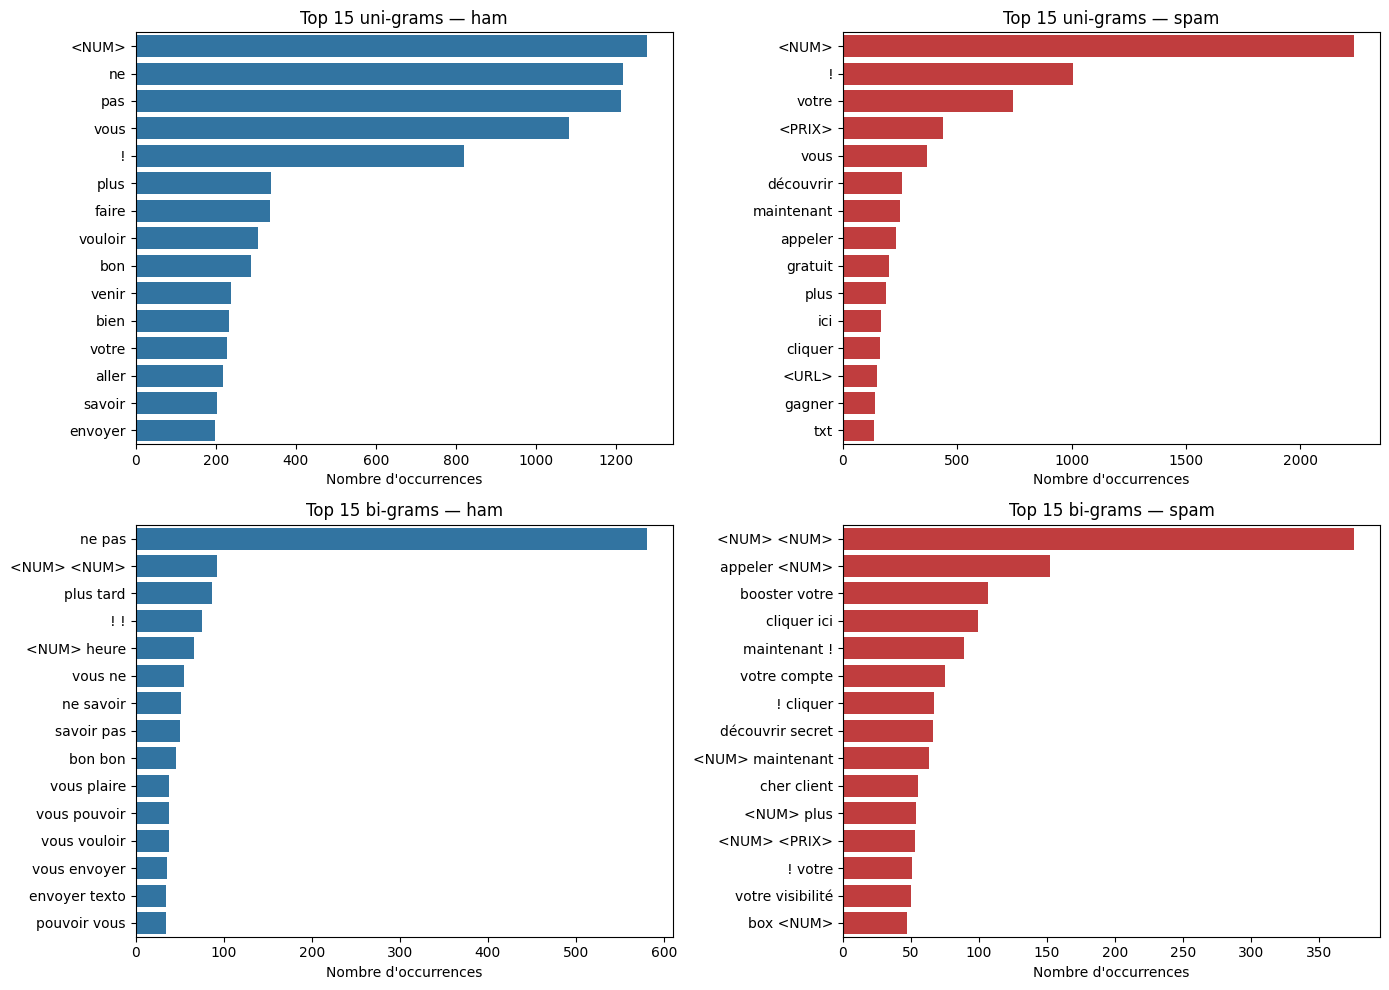

In [15]:
from sklearn.feature_extraction.text import CountVectorizer


def top_ngrams(textes, n, k=15):
    """Renvoie les k n-grams les plus fréquents d'une liste de textes.

    Paramètres : textes (Series de str), les messages nettoyés ;
                 n (int), la taille des n-grams (1 = mots seuls, 2 = paires de mots) ;
                 k (int), le nombre de n-grams à renvoyer.
    Retour     : Series pandas, n-gram -> nombre d'occurrences, triée par ordre décroissant.
    """
    # token_pattern=r'\S+' : un token = tout ce qui est entre deux espaces.
    #   Le motif par défaut de scikit-learn supprimerait '!' et '<URL>'.
    # lowercase=False : le texte est déjà en minuscules, et on garde '<URL>' en majuscules.
    cv = CountVectorizer(ngram_range=(n, n), token_pattern=r'\S+', lowercase=False)
    X = cv.fit_transform(textes)             # matrice messages x n-grams (comptages)
    frequences = X.sum(axis=0).A1            # somme sur tous les messages -> total par n-gram
    return (pd.Series(frequences, index=cv.get_feature_names_out())
              .sort_values(ascending=False)
              .head(k))


# Grille 2 x 2 : lignes = uni-grams / bi-grams, colonnes = ham / spam
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for col, label in enumerate(['ham', 'spam']):
    textes = df.loc[df['label'] == label, 'text_nettoye']
    couleur = 'tab:blue' if label == 'ham' else 'tab:red'
    for row, n in enumerate([1, 2]):
        top = top_ngrams(textes, n)
        sns.barplot(x=top.values, y=top.index, ax=axes[row, col], color=couleur)
        axes[row, col].set_title(f"Top 15 {'uni' if n == 1 else 'bi'}-grams — {label}")
        axes[row, col].set_xlabel("Nombre d'occurrences")
        axes[row, col].set_ylabel('')
plt.tight_layout()
plt.show()

In [16]:
# Sauvegarde du fichier de sortie nettoyé (livrable "fichier de données de sortie")
#   source       : Kinoux ou SMS Collection
#   text         : message brut d'origine
#   text_masque  : après l'étape 2.A (regex)
#   text_nettoye : après l'étape 2.B (spaCy), c'est cette colonne qui sera vectorisée
#   label        : ham / spam
colonnes = ['source', 'text', 'text_masque', 'text_nettoye', 'label']
df[colonnes].to_csv('data/sms_nettoye.csv', index=False, encoding='utf-8')
print('Fichier enregistré : data/sms_nettoye.csv', df[colonnes].shape)

Fichier enregistré : data/sms_nettoye.csv (6105, 5)


## Étape 3 — Représentation numérique et modélisation

### 3.A Découpage apprentissage / test et vectorisation TF-IDF

Un modèle de machine learning ne lit pas du texte, il lit des **nombres**. Il faut donc transformer chaque message en vecteur.

**Le TF-IDF** donne à chaque mot d'un message un poids qui combine deux idées :
- **TF** (*Term Frequency*) : le mot est-il fréquent **dans ce message** ? Si oui, il est important pour ce message ;
- **IDF** (*Inverse Document Frequency*) : le mot est-il rare **dans l'ensemble du corpus** ? Si oui, il est discriminant. Un mot présent partout reçoit un poids plus faible qu'un mot rare comme *suspension*.

On obtient une matrice de taille **(nombre de messages × nombre de n-grams)**. Elle est essentiellement remplie de zéros, car chaque message n'utilise qu'une petite partie du vocabulaire.

**Découpage 80 / 20, stratifié sur la classe ET la source.** Chaque partie garde ainsi les mêmes proportions de spams Kinoux, de ham Kinoux, de spams SMS Collection, etc. Sans cela, le hasard pourrait mettre presque tous les messages Kinoux d'un seul côté.

**L'ordre des opérations est important : on découpe AVANT de vectoriser.**
Le TF-IDF calcule l'IDF à partir des textes qu'on lui donne. S'il voyait les messages de test, des informations du test « fuiteraient » dans l'apprentissage (*data leakage*), et les scores seraient trop optimistes. On l'ajuste donc (`fit`) **uniquement** sur les données d'apprentissage, puis on l'applique (`transform`) au test.

**Paramètres choisis :**
- `ngram_range=(1, 2)` : uni-grams **et** bi-grams (la validation croisée de l'étape 3.B testera aussi les uni-grams seuls) ;
- `min_df=2` : on ignore les n-grams présents dans un seul message. Ce sont souvent des fautes ou des cas uniques, qui ajoutent du bruit sans aider à généraliser ;
- `sublinear_tf=True` : on remplace le comptage brut par `1 + log(tf)`, pour qu'un mot répété 5 fois ne pèse pas 5 fois plus.

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# X = les textes nettoyés (entrée du modèle), y = la cible codée en 0/1
X = df['text_nettoye']
y = (df['label'] == 'spam').astype(int)      # spam -> 1, ham -> 0

# Découpage 80 % apprentissage / 20 % test
#   stratify : on garde les mêmes proportions de chaque couple (source, classe) dans les deux parties
#   random_state=42 : découpage identique à chaque exécution (reproductibilité)
strates = df['source'] + ' / ' + df['label']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=strates, random_state=42
)
print('Apprentissage :', len(X_train), 'messages | spams :', y_train.sum(), f'({y_train.mean():.1%})')
print('Test          :', len(X_test), 'messages | spams :', y_test.sum(), f'({y_test.mean():.1%})')
strates.loc[X_test.index].value_counts().rename('messages dans le test')

Apprentissage : 4884 messages | spams : 912 (18.7%)
Test          : 1221 messages | spams : 228 (18.7%)


SMS Collection / ham     893
SMS Collection / spam    128
Kinoux / spam            100
Kinoux / ham             100
Name: messages dans le test, dtype: int64

In [18]:
# Vectoriseur TF-IDF
#   token_pattern=r'\S+' et lowercase=False : comme pour top_ngrams(), pour garder '!' et '<URL>'
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
    token_pattern=r'\S+',
    lowercase=False,
)

# fit_transform sur l'apprentissage : apprend le vocabulaire et l'IDF, puis transforme
X_train_tfidf = tfidf.fit_transform(X_train)
# transform seul sur le test : réutilise le vocabulaire et l'IDF appris, sans rien réapprendre
X_test_tfidf = tfidf.transform(X_test)

print('Matrice apprentissage :', X_train_tfidf.shape, '(messages x n-grams)')
print('Matrice test          :', X_test_tfidf.shape)
taux_remplissage = X_train_tfidf.nnz / (X_train_tfidf.shape[0] * X_train_tfidf.shape[1])
print(f'Cases non nulles      : {taux_remplissage:.2%}  -> matrice creuse (sparse)')

# Aperçu : les n-grams les plus "pesants" d'un spam d'apprentissage
i = np.flatnonzero(y_train.values == 1)[0]
poids = pd.Series(X_train_tfidf[i].toarray().ravel(), index=tfidf.get_feature_names_out())
print('\nMessage :', X_train.iloc[i])
poids[poids > 0].sort_values(ascending=False).round(3)

Matrice apprentissage :

 (4884, 7287) (messages x n-grams)
Matrice test          : (1221, 7287)
Cases non nulles      : 0.15%  -> matrice creuse (sparse)

Message : <NUM> jour lancement euro <NUM> ! informer dernier actualité résultat quotidien désabonnement envoyer get euro <NUM>


euro <NUM>            0.410
euro                  0.401
résultat quotidien    0.258
! informer            0.258
lancement             0.258
envoyer get           0.258
quotidien             0.249
désabonnement         0.232
informer              0.218
get                   0.206
<NUM> !               0.200
<NUM> jour            0.187
résultat              0.184
<NUM>                 0.159
dernier               0.156
jour                  0.138
envoyer               0.128
!                     0.077
dtype: float64

### 3.B Comparaison de 4 algorithmes et choix du meilleur

On compare **4 familles de modèles** bien différentes :

| Modèle | Principe | Intérêt |
|---|---|---|
| **Régression logistique** | Somme pondérée des poids TF-IDF, transformée en probabilité de spam (fonction sigmoïde) | Modèle de **référence** : simple, rapide et interprétable (un coefficient par n-gram) |
| **k plus proches voisins (k-NN)** | Un message prend la classe majoritaire de ses *k* messages d'apprentissage les plus **proches** (distance cosinus entre vecteurs TF-IDF) | Aucune hypothèse sur la forme de la frontière ; référence « par similarité » |
| **SVM linéaire** | Cherche la frontière qui sépare ham et spam avec la **plus grande marge** possible | Réputé très performant sur le texte, qui a beaucoup de dimensions et des matrices creuses |
| **Random Forest** | Vote de plusieurs centaines d'**arbres de décision**, chacun entraîné sur un échantillon différent | Non linéaire : capte des combinaisons de mots |

**Gestion du déséquilibre (environ 1 spam pour 4 ham).** Par défaut, un modèle cherche à faire le moins d'erreurs possible au total. Il peut alors « sacrifier » la classe minoritaire (les spams). Le paramètre **`class_weight='balanced'`** donne à chaque spam un poids plus fort dans l'apprentissage, proportionnel à sa rareté. On le teste dans la grille (`None` ou `'balanced'`) pour les trois modèles qui le permettent. Le k-NN n'a pas ce paramètre. L'alternative SMOTE est comparée à l'étape 3.C.

**Méthode de sélection : validation croisée à 5 plis (`GridSearchCV`)**
1. Le jeu d'**apprentissage** est coupé en 5 parts. Le modèle est entraîné sur 4 parts et évalué sur la 5ᵉ, et on recommence 5 fois en changeant de part. Le score retenu est la **moyenne des 5** (± l'écart-type, qui mesure la stabilité).
2. Pour chaque modèle, on teste plusieurs **hyperparamètres** et on garde la meilleure combinaison.
3. Le TF-IDF et le modèle sont réunis dans un **`Pipeline`**. Ainsi, le TF-IDF est réajusté à l'intérieur de chaque pli, uniquement sur les 4 parts d'apprentissage, et il n'y a aucune fuite de données. La cellule 3.A ci-dessus servait à illustrer le TF-IDF. Ici, c'est le pipeline qui s'en charge.
4. Le **meilleur modèle** est celui qui a le meilleur **F1 moyen en validation croisée** (F1 de la classe spam). Le jeu de **test** n'est utilisé qu'**à la fin**, pour l'évaluation finale.

**Pourquoi le F1 ?** Il combine la **précision** et le **rappel** :

| Métrique | Question à laquelle elle répond (*positif* = spam) |
|---|---|
| **Précision** | Parmi les messages **signalés comme spam**, quelle part l'est vraiment ? Une précision faible signifie que de vrais messages sont bloqués à tort. |
| **Rappel** | Parmi les **vrais spams**, quelle part a été détectée ? Un rappel faible signifie que des arnaques passent. |
| **F1-score** | Moyenne harmonique de la précision et du rappel : il est élevé seulement si **les deux** le sont. |
| **AUC-ROC** | Capacité à **classer** les spams au-dessus des ham, quel que soit le seuil. 1 = parfait, 0,5 = hasard. |
| **Matrice de confusion** | Nombre de messages bien et mal classés, dans chaque sens. |

Avec des classes déséquilibrées, l'*accuracy* seule est trompeuse : répondre toujours « ham » donnerait plus de 80 % d'accuracy, mais un F1 de 0.

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier


def creer_pipeline(classifieur):
    """Assemble un TF-IDF et un classifieur dans un même Pipeline scikit-learn.

    Paramètre : classifieur, un modèle scikit-learn non entraîné.
    Retour    : Pipeline, qui fait 'texte nettoyé -> TF-IDF -> prédiction' en un seul objet.
                Les réglages du TF-IDF sont ceux de l'étape 3.A.
    """
    return Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True,
                                  token_pattern=r'\S+', lowercase=False)),   # étape nommée 'tfidf'
        ('clf', classifieur),                                                # étape nommée 'clf'
    ])


# --- Grilles d'hyperparamètres : les réglages que GridSearchCV va essayer ---
#
# Syntaxe des clés : '<nom de l'étape du Pipeline>__<nom du paramètre>' (double tiret bas '__')
#   'tfidf__ngram_range' -> le paramètre ngram_range de l'étape 'tfidf' (le TfidfVectorizer)
#   'clf__C'             -> le paramètre C de l'étape 'clf' (le classifieur)
#
# 'tfidf__ngram_range': [(1, 1), (1, 2)] -> mots seuls, ou mots seuls + paires de mots.
#   Plutôt que de supposer que les bi-grams aident (étape 2.C), on laisse la validation croisée trancher.
# 'clf__C' : force de régularisation (petit C = modèle plus simple et prudent,
#            grand C = modèle qui colle davantage aux données d'apprentissage, risque de sur-apprentissage).
# 'clf__class_weight' : None (tous les messages pèsent pareil) ou 'balanced' (les spams, plus rares, pèsent plus).
#
# GridSearchCV teste TOUTES les combinaisons de la grille :
#   ex. régression logistique : 2 ngram_range x 4 valeurs de C x 2 class_weight = 16 combinaisons,
#   chacune évaluée sur 5 plis -> 80 entraînements. La combinaison au meilleur F1 moyen est retenue.
poids = [None, 'balanced']
modeles = {
    'Régression logistique': (
        creer_pipeline(LogisticRegression(max_iter=2000, random_state=42)),
        {'tfidf__ngram_range': [(1, 1), (1, 2)], 'clf__C': [0.1, 1, 10, 100],
         'clf__class_weight': poids},
    ),
    'k-NN': (
        # metric='cosine' : distance adaptée au TF-IDF (compare la direction des vecteurs, pas leur longueur)
        # weights='distance' : un voisin proche compte plus qu'un voisin lointain
        creer_pipeline(KNeighborsClassifier(metric='cosine')),
        {'tfidf__ngram_range': [(1, 1), (1, 2)], 'clf__n_neighbors': [3, 5, 11, 21],
         'clf__weights': ['uniform', 'distance']},
    ),
    'SVM linéaire': (
        creer_pipeline(LinearSVC(random_state=42)),
        {'tfidf__ngram_range': [(1, 1), (1, 2)], 'clf__C': [0.01, 0.1, 1, 10],
         'clf__class_weight': poids},
    ),
    'Random Forest': (
        creer_pipeline(RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)),
        # max_depth : profondeur maximale des arbres (None = sans limite)
        {'tfidf__ngram_range': [(1, 1), (1, 2)], 'clf__max_depth': [None, 50],
         'clf__class_weight': poids},
    ),
}

# Validation croisée à 5 plis, stratifiée (chaque pli garde la même proportion de spams)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metriques = {'F1': 'f1', 'précision': 'precision', 'rappel': 'recall', 'AUC-ROC': 'roc_auc'}

recherches = {}   # nom du modèle -> GridSearchCV entraîné
for nom, (pipeline, grille) in modeles.items():
    # refit='F1' : le meilleur réglage est choisi sur le F1, puis réentraîné sur tout l'apprentissage
    recherche = GridSearchCV(pipeline, grille, cv=cv, scoring=metriques, refit='F1', n_jobs=-1)
    recherche.fit(X_train, y_train)   # X_train = textes nettoyés (le Pipeline fait le TF-IDF)
    recherches[nom] = recherche
    print(f'{nom:<22} meilleur F1 (CV) = {recherche.best_score_:.3f}   réglages : {recherche.best_params_}')

Régression logistique  meilleur F1 (CV) = 0.951   réglages : {'clf__C': 100, 'clf__class_weight': None, 'tfidf__ngram_range': (1, 1)}


k-NN                   meilleur F1 (CV) = 0.901   réglages : {'clf__n_neighbors': 5, 'clf__weights': 'distance', 'tfidf__ngram_range': (1, 1)}


SVM linéaire           meilleur F1 (CV) = 0.958   réglages : {'clf__C': 1, 'clf__class_weight': None, 'tfidf__ngram_range': (1, 1)}


Random Forest          meilleur F1 (CV) = 0.952   réglages : {'clf__class_weight': 'balanced', 'clf__max_depth': 50, 'tfidf__ngram_range': (1, 1)}


,F1,précision,rappel,AUC-ROC
modèle,,,,
Régression logistique,0.951 ± 0.016,0.967 ± 0.009,0.936 ± 0.025,0.994 ± 0.003
k-NN,0.901 ± 0.012,0.956 ± 0.014,0.852 ± 0.021,0.967 ± 0.008
SVM linéaire,0.958 ± 0.014,0.973 ± 0.009,0.944 ± 0.023,0.995 ± 0.003
Random Forest,0.952 ± 0.009,0.986 ± 0.010,0.921 ± 0.010,0.994 ± 0.003


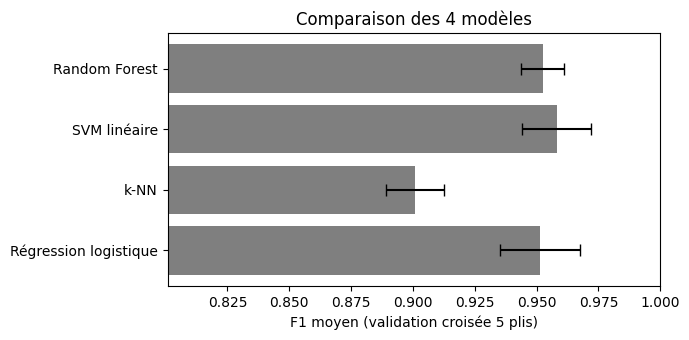

Meilleur modèle : SVM linéaire (F1 CV = 0.958)
Réglages retenus : {'clf__C': 1, 'clf__class_weight': None, 'tfidf__ngram_range': (1, 1)}


In [20]:
# Tableau comparatif : les scores moyens en validation croisée du meilleur réglage de chaque modèle
lignes = []
for nom, recherche in recherches.items():
    res = recherche.cv_results_          # tous les scores de tous les réglages testés
    i = recherche.best_index_            # position du meilleur réglage
    ligne = {'modèle': nom}
    for m in metriques:
        # moyenne ± écart-type sur les 5 plis : l'écart-type mesure la stabilité du modèle
        ligne[m] = f"{res[f'mean_test_{m}'][i]:.3f} ± {res[f'std_test_{m}'][i]:.3f}"
    lignes.append(ligne)
comparaison_cv = pd.DataFrame(lignes).set_index('modèle')
display(comparaison_cv)

# Graphique : F1 moyen de chaque modèle, avec barre d'erreur = écart-type sur les 5 plis
f1_moyen = {nom: r.cv_results_['mean_test_F1'][r.best_index_] for nom, r in recherches.items()}
f1_std = {nom: r.cv_results_['std_test_F1'][r.best_index_] for nom, r in recherches.items()}
plt.figure(figsize=(7, 3.5))
plt.barh(list(f1_moyen), list(f1_moyen.values()), xerr=list(f1_std.values()), color='tab:gray', capsize=4)
plt.xlim(min(f1_moyen.values()) - 0.1, 1)
plt.xlabel('F1 moyen (validation croisée 5 plis)')
plt.title('Comparaison des 4 modèles')
plt.tight_layout()
plt.show()

# Choix du meilleur modèle : le F1 moyen le plus élevé en validation croisée.
# En cas d'égalité, max() garde le premier modèle du dictionnaire 'modeles' :
# la régression logistique, le plus simple et le plus interprétable (principe de parcimonie).
nom_meilleur = max(f1_moyen, key=f1_moyen.get)
meilleur_modele = recherches[nom_meilleur].best_estimator_   # Pipeline TF-IDF + modèle, réentraîné
print(f'Meilleur modèle : {nom_meilleur} (F1 CV = {f1_moyen[nom_meilleur]:.3f})')
print('Réglages retenus :', recherches[nom_meilleur].best_params_)

In [21]:
# Effet de class_weight : pour chaque modèle, meilleur F1 (CV) obtenu SANS puis AVEC 'balanced'
lignes = []
for nom, recherche in recherches.items():
    res = pd.DataFrame(recherche.cv_results_)
    if 'param_clf__class_weight' not in res:
        continue   # le k-NN n'a pas ce paramètre
    poids_txt = res['param_clf__class_weight'].astype(str)
    for p in ['None', 'balanced']:
        meilleur = res[poids_txt == p].sort_values('mean_test_F1', ascending=False).iloc[0]
        lignes.append({'modèle': nom, 'class_weight': p,
                       'F1': meilleur['mean_test_F1'], 'précision': meilleur['mean_test_précision'],
                       'rappel': meilleur['mean_test_rappel']})
pd.DataFrame(lignes).set_index(['modèle', 'class_weight']).round(3)

F1  précision  rappel
modèle                class_weight                          
Régression logistique None          0.951      0.967   0.936
                      balanced      0.949      0.948   0.951
SVM linéaire          None          0.958      0.973   0.944
                      balanced      0.952      0.952   0.952
Random Forest         None          0.951      0.983   0.921
                      balanced      0.952      0.986   0.921

### 3.C Déséquilibre des classes : `class_weight` ou SMOTE ?

**SMOTE** (*Synthetic Minority Over-sampling Technique*) est l'autre solution classique au déséquilibre. Au lieu de donner plus de poids aux spams, il **crée de nouveaux spams artificiels** dans l'espace TF-IDF : pour un spam donné, il choisit un de ses plus proches voisins spams et fabrique un point intermédiaire entre les deux. L'apprentissage se fait alors sur des classes équilibrées.

**Point important :** SMOTE ne doit être appliqué **qu'aux données d'apprentissage** de chaque pli, jamais aux données d'évaluation. On utilise donc le `Pipeline` de la bibliothèque `imbalanced-learn`, qui applique SMOTE pendant `fit` mais pas pendant `predict`.

On compare, avec la validation croisée et les mêmes réglages que le modèle retenu, trois variantes : sans correction, avec `class_weight='balanced'`, avec SMOTE.

In [22]:
from imblearn.pipeline import Pipeline as PipelineImb
from imblearn.over_sampling import SMOTE
from sklearn.base import clone
from sklearn.model_selection import cross_validate

# Réglages retenus pour le meilleur modèle (sans le paramètre class_weight, qu'on fait varier ici)
reglages = {k: v for k, v in recherches[nom_meilleur].best_params_.items() if k != 'clf__class_weight'}
base = clone(meilleur_modele).set_params(**reglages)

variantes = {'Sans correction': clone(base), 'SMOTE': None}
if 'class_weight' in base.named_steps['clf'].get_params():
    variantes = {
        'Sans correction': clone(base).set_params(clf__class_weight=None),
        "class_weight='balanced'": clone(base).set_params(clf__class_weight='balanced'),
        'SMOTE': None,
    }
    base_smote = clone(base).set_params(clf__class_weight=None)
else:
    base_smote = clone(base)

# SMOTE est inséré ENTRE le TF-IDF et le classifieur : il crée des spams artificiels dans l'espace TF-IDF
variantes['SMOTE'] = PipelineImb([
    ('tfidf', base_smote.named_steps['tfidf']),
    ('smote', SMOTE(random_state=42)),
    ('clf', base_smote.named_steps['clf']),
])

lignes = []
for nom, modele in variantes.items():
    scores = cross_validate(modele, X_train, y_train, cv=cv, scoring=metriques, n_jobs=-1)
    lignes.append({'variante': nom, **{m: f"{scores[f'test_{m}'].mean():.3f} ± {scores[f'test_{m}'].std():.3f}"
                                         for m in metriques}})
pd.DataFrame(lignes).set_index('variante')

,F1,précision,rappel,AUC-ROC
variante,,,,
Sans correction,0.958 ± 0.014,0.973 ± 0.009,0.944 ± 0.023,0.995 ± 0.003
class_weight='balanced',0.946 ± 0.017,0.936 ± 0.020,0.956 ± 0.016,0.994 ± 0.003
SMOTE,0.949 ± 0.016,0.947 ± 0.018,0.952 ± 0.017,0.994 ± 0.003


### 3.D Évaluation finale et interprétation du meilleur modèle

Le modèle retenu est réentraîné sur tous les messages d'apprentissage, puis évalué **une seule fois** sur les messages de test. Ce score final est une estimation honnête de ses performances sur de nouveaux messages. On le détaille aussi **par source**, pour vérifier que le modèle fonctionne sur les deux types de messages.

===== SVM linéaire — jeu de test (1221 messages) =====
              precision    recall  f1-score   support

         ham      0.988     0.996     0.992       993
        spam      0.982     0.947     0.964       228

    accuracy                          0.987      1221
   macro avg      0.985     0.972     0.978      1221
weighted avg      0.987     0.987     0.987      1221

AUC-ROC : 0.995


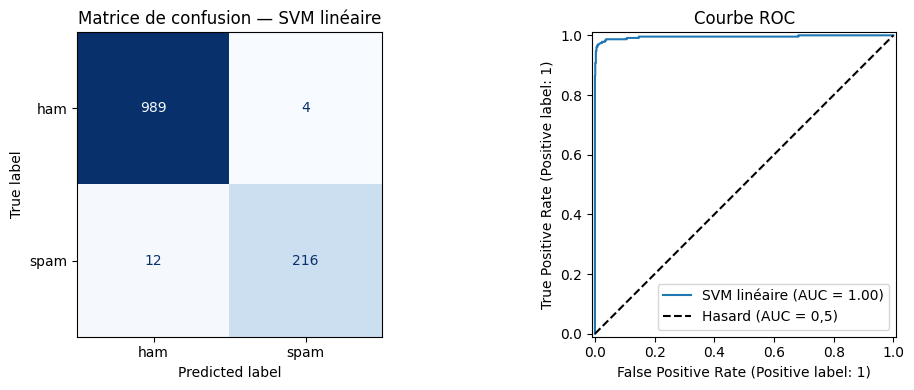

In [23]:
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, roc_auc_score, f1_score, precision_score,
                             recall_score, accuracy_score)


def score_spam(modele, X_te):
    """Score de "spam" d'un modèle : une probabilité s'il sait la donner, sinon un score de décision
    (c'est le cas du SVM linéaire, qui n'a pas de predict_proba)."""
    if hasattr(modele, 'predict_proba'):
        return modele.predict_proba(X_te)[:, 1]   # colonne 1 = probabilité d'être spam
    return modele.decision_function(X_te)


def evaluer(modele, X_te, y_te, nom):
    """Évalue un modèle déjà entraîné sur le jeu de test : rapport, matrice de confusion, courbe ROC.

    Paramètres : modele, un Pipeline entraîné (TF-IDF + classifieur) ;
                 X_te, les textes nettoyés du test ; y_te, les vraies étiquettes (0/1) ;
                 nom (str), le nom du modèle (pour les titres).
    Retour     : array, les classes prédites (0/1), pour analyser les erreurs ensuite.
    """
    y_pred = modele.predict(X_te)
    y_score = score_spam(modele, X_te)

    print(f'===== {nom} — jeu de test ({len(y_te)} messages) =====')
    print(classification_report(y_te, y_pred, target_names=['ham', 'spam'], digits=3))
    print(f'AUC-ROC : {roc_auc_score(y_te, y_score):.3f}')

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred), display_labels=['ham', 'spam']).plot(
        ax=axes[0], cmap='Blues', colorbar=False)
    axes[0].set_title(f'Matrice de confusion — {nom}')
    RocCurveDisplay.from_predictions(y_te, y_score, ax=axes[1], name=nom)
    axes[1].plot([0, 1], [0, 1], 'k--', label='Hasard (AUC = 0,5)')
    axes[1].set_title('Courbe ROC')
    axes[1].legend()
    plt.tight_layout()
    plt.show()
    return y_pred


# Évaluation finale du modèle retenu, sur les messages de test jamais vus jusqu'ici
y_pred_test = evaluer(meilleur_modele, X_test, y_test, nom_meilleur)

In [24]:
def scores_par_groupe(y_vrai, y_pred, y_score, groupes):
    """Calcule les principales métriques séparément pour chaque groupe (ici : chaque source).

    Paramètres : y_vrai, y_pred, y_score (Series ou arrays alignés) ; groupes (Series), le groupe de chaque message.
    Retour     : DataFrame, une ligne par groupe.
    """
    lignes = []
    for g in groupes.unique():
        m = (groupes == g).values
        lignes.append({
            'source': g, 'messages': m.sum(), 'spams': int(y_vrai[m].sum()),
            'précision': precision_score(y_vrai[m], y_pred[m], zero_division=0),
            'rappel': recall_score(y_vrai[m], y_pred[m]),
            'F1': f1_score(y_vrai[m], y_pred[m]),
            'accuracy': accuracy_score(y_vrai[m], y_pred[m]),
            'AUC-ROC': roc_auc_score(y_vrai[m], y_score[m]),
        })
    return pd.DataFrame(lignes).set_index('source').round(3)


source_test = df.loc[X_test.index, 'source']
scores_par_groupe(y_test.values, y_pred_test, score_spam(meilleur_modele, X_test), source_test)

,messages,spams,précision,rappel,F1,accuracy,AUC-ROC
source,,,,,,,
Kinoux,200,100,1.000,0.980,0.990,0.990,0.991
SMS Collection,1021,128,0.967,0.922,0.944,0.986,0.998


In [25]:
# Analyse des erreurs : quels messages du test le modèle a-t-il mal classés ?
erreurs = pd.DataFrame({
    'source': source_test,
    'message': df.loc[X_test.index, 'text'],           # texte d'origine (plus lisible que le nettoyé)
    'vrai': y_test.map({0: 'ham', 1: 'spam'}),
    'prédit': pd.Series(y_pred_test, index=X_test.index).map({0: 'ham', 1: 'spam'}),
})
erreurs = erreurs[erreurs['vrai'] != erreurs['prédit']]

print(f"{len(erreurs)} erreur(s) sur {len(X_test)} messages de test")
print("  - faux positifs (ham classé spam = vrai message bloqué) :", (erreurs['vrai'] == 'ham').sum())
print("  - faux négatifs (spam classé ham = arnaque non détectée) :", (erreurs['vrai'] == 'spam').sum())
print('\nErreurs par source :')
print(pd.crosstab(erreurs['source'], erreurs['vrai'].map({'ham': 'faux positifs', 'spam': 'faux négatifs'})))
erreurs.sort_values(['vrai', 'source'])

16 erreur(s) sur 1221 messages de test
  - faux positifs (ham classé spam = vrai message bloqué) : 4
  - faux négatifs (spam classé ham = arnaque non détectée) : 12

Erreurs par source :
vrai            faux négatifs  faux positifs
source                                      
Kinoux                      2              0
SMS Collection             10              4


,source,message,vrai,prédit
4618,SMS Collection,Textes illimités. Minutes limitées.,ham,spam
2609,SMS Collection,"C'est 6 livres pour entrer, c'est bon?",ham,spam
2903,SMS Collection,Avez-vous pratiqué votre curtsey?,ham,spam
4480,SMS Collection,"C'est 6 £ pour entrer, c'est bon?",ham,spam
486,Kinoux,"Vends bureau spacieux, affaires en or!",spam,ham
754,Kinoux,"Appart super chic, reduc folle! Contactez-moi.",spam,ham
3306,SMS Collection,Devinez qui suis-je?C'est la première fois que j'ai créé une page web WWW.ASJESUS.COM a lu tout ce que j'ai écrit. J'attends vos avis. Je veux être votre ami 1/1,spam,ham
4485,SMS Collection,2/2 146tf150p,spam,ham
3044,SMS Collection,FreeMsg: Hey - I'm Buffy. 25 et aimer pour satisfaire les hommes. Accueil seul sentiment randy. Réponse 2 C mon PIX! QlynnBV Help08700621170150p a msg Envoyer arrêt pour arrêter txts,spam,ham
1644,SMS Collection,88800 et 89034 sont des services téléphoniques premium au numéro 08718711108,spam,ham


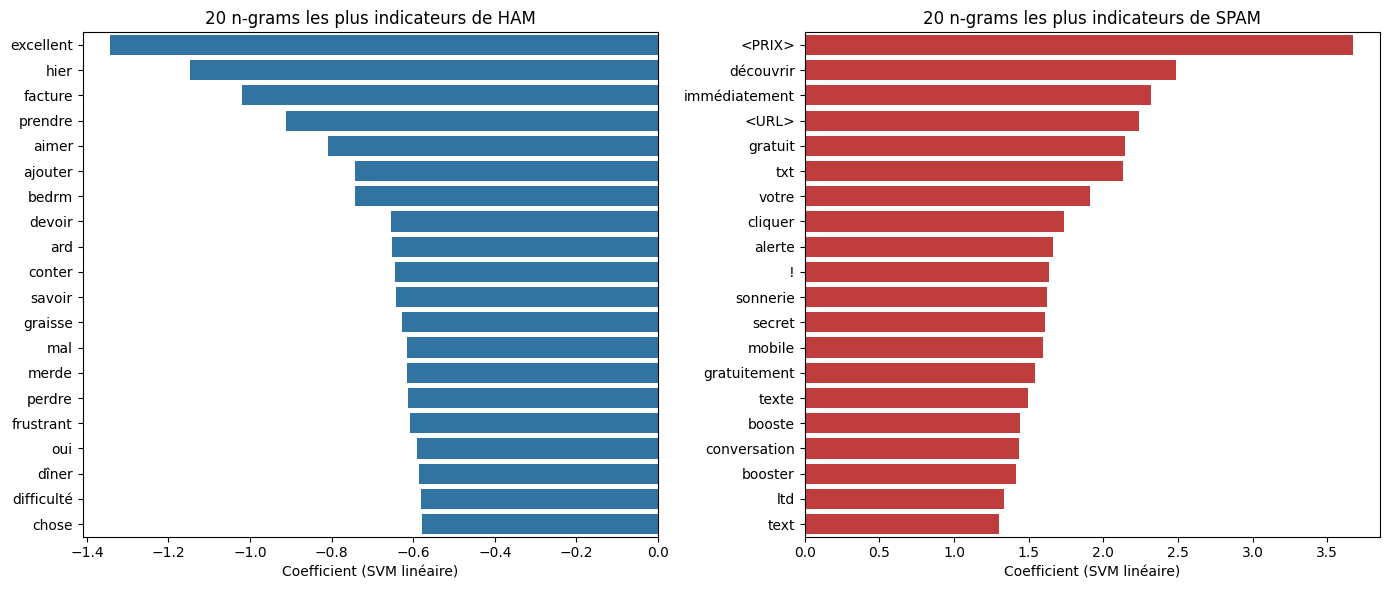

In [26]:
# Interprétation : quels n-grams pèsent le plus dans la décision du modèle retenu ?
vocab = meilleur_modele.named_steps['tfidf'].get_feature_names_out()
clf = meilleur_modele.named_steps['clf']

if hasattr(clf, 'coef_'):
    # Modèle linéaire (régression logistique ou SVM) : un coefficient par n-gram.
    # Coefficient positif -> pousse vers SPAM ; négatif -> pousse vers HAM.
    coefficients = pd.Series(clf.coef_[0], index=vocab)
    top_spam = coefficients.sort_values(ascending=False).head(20)
    top_ham = coefficients.sort_values().head(20)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    sns.barplot(x=top_ham.values, y=top_ham.index, ax=axes[0], color='tab:blue')
    axes[0].set_title('20 n-grams les plus indicateurs de HAM')
    sns.barplot(x=top_spam.values, y=top_spam.index, ax=axes[1], color='tab:red')
    axes[1].set_title('20 n-grams les plus indicateurs de SPAM')
    for ax in axes:
        ax.set_xlabel(f'Coefficient ({nom_meilleur})')
        ax.set_ylabel('')
else:
    # Random Forest : importance de chaque n-gram (sans sens ham/spam, seulement "utile ou non")
    importances = pd.Series(clf.feature_importances_, index=vocab).sort_values(ascending=False).head(20)
    plt.figure(figsize=(7, 6))
    sns.barplot(x=importances.values, y=importances.index, color='tab:green')
    plt.title('20 n-grams les plus importants (Random Forest)')
    plt.xlabel('Importance')
    plt.ylabel('')
plt.tight_layout()
plt.show()

#### Lecture des résultats de l'étape 3

**Comparaison des modèles (validation croisée).**
- Le **SVM linéaire** obtient le meilleur F1 (0,958 ± 0,014), devant la Random Forest (0,952) et la régression logistique (0,951). Les écarts entre ces trois modèles sont **inférieurs à leurs écarts-types** : ils sont pratiquement à égalité.
- Le **k-NN** est nettement derrière (F1 = 0,901). Sa précision reste correcte (0,956), mais son **rappel est faible (0,852)** : un spam rédigé différemment des spams déjà vus n'a pas de « voisin » proche et passe inaperçu.
- Réglages retenus pour le SVM : `C = 1`, **uni-grams seuls**, sans `class_weight`. Les bi-grams n'améliorent pas le F1 : les mots seuls suffisent.

**Déséquilibre des classes.** Les deux corrections (`class_weight='balanced'` et SMOTE) font ce qu'on attend d'elles : elles **augmentent le rappel** (0,944 → 0,956 et 0,952) mais **diminuent la précision** (0,973 → 0,936 et 0,947), si bien que le F1 baisse. Avec environ 19 % de spams, le déséquilibre est **modéré** et le SVM le gère déjà bien. On garde donc le modèle sans correction. Si la priorité était de ne laisser passer **aucune** arnaque, quitte à bloquer un peu plus de vrais messages, `class_weight='balanced'` serait le meilleur choix.

**Évaluation finale sur le test (1 221 messages, 228 spams).**
- F1 spam = **0,964**, précision = 0,982, rappel = 0,947, AUC-ROC = 0,995.
- L'**accuracy (0,987) est ici différente du F1 (0,964)**. Avec des classes déséquilibrées, l'accuracy est tirée vers le haut par les nombreux ham faciles à reconnaître. C'est pourquoi le F1 de la classe spam est le critère principal.
- **16 erreurs** : 4 faux positifs (vrais messages bloqués) et 12 faux négatifs (spams non détectés).
- **Par source** : F1 = 0,990 sur Kinoux et 0,944 sur SMS Collection, plus difficile car ses ham sont de vrais SMS très variés.

**Analyse des erreurs.**
- Les **4 faux positifs** sont des SMS légitimes qui ressemblent à de la publicité : « C'est 6 £ pour entrer, c'est bon ? » (deux variantes, à cause de la balise `<PRIX>`), « Textes illimités. Minutes limitées. », « Avez-vous pratiqué votre curtsey ? » (*votre*). Tous ont un score faible (de 0,01 à 0,36) : ce sont des cas limites.
- Les **12 faux négatifs** sont surtout des spams **courts ou atypiques** (« 2/2 146tf150p », les deux petites annonces de Kinoux) ou **sans montant ni lien**. **7 sur 12 ont un score entre −0,3 et 0** : ils sont **juste du mauvais côté de la frontière**, et un seuil un peu plus bas les rattraperait.

**Coefficients du modèle.**
- Côté **spam** : la balise `<PRIX>` (de loin la plus forte), *découvrir*, *immédiatement*, `<URL>`, *gratuit*, *txt*, *votre*, *cliquer*, *alerte*, *!*, *sonnerie*. On retrouve les marqueurs du smishing : **un gain, un lien, l'adresse directe et l'urgence**. Le masquage de l'étape 2.A est donc essentiel : ce sont les balises, et non des montants ou liens précis, qui portent la décision.
- Côté **ham** : *excellent*, *hier*, *facture*, *prendre*, *aimer*, *devoir*, *savoir*. Contrairement à la version avec Kinoux seul, où les ham étaient surtout reconnus par le vocabulaire de l'**opinion**, le modèle s'appuie maintenant aussi sur le vocabulaire de la **vie quotidienne**.
- Quelques mots de ce côté ne viennent que d'**un seul message** d'apprentissage (*bedrm*, *ard*, *graisse*) : c'est un léger sur-apprentissage, sans conséquence sur les scores, mais qu'une régularisation plus forte (C plus petit) réduirait.

## Étape 4 — Généralisation et utilisation sur de nouveaux messages

### 4.A Un modèle appris sur une source fonctionne-t-il sur l'autre ?

Les deux jeux de données ont été construits de façon très différente. Pour mesurer l'intérêt de les **combiner**, on entraîne le modèle retenu (mêmes réglages) sur **une seule source**, puis on l'évalue sur la partie test de **chaque** source :

- appris sur Kinoux seul → testé sur Kinoux et sur SMS Collection ;
- appris sur SMS Collection seul → testé sur les deux ;
- appris sur les deux (le modèle final) → testé sur les deux.

Si un modèle appris sur une source échoue sur l'autre, c'est qu'il a appris des particularités de son corpus plutôt que ce qu'est un spam.

In [27]:
source_train = df.loc[X_train.index, 'source']
lignes = []
for apprentissage in ['Kinoux', 'SMS Collection', 'Les deux']:
    masque = (source_train == apprentissage) if apprentissage != 'Les deux' else (source_train == source_train)
    modele = clone(meilleur_modele).fit(X_train[masque], y_train[masque])
    for test in ['Kinoux', 'SMS Collection']:
        m = (source_test == test)
        pred = modele.predict(X_test[m])
        lignes.append({'appris sur': apprentissage, 'testé sur': test,
                       'F1': f1_score(y_test[m], pred), 'précision': precision_score(y_test[m], pred, zero_division=0),
                       'rappel': recall_score(y_test[m], pred)})
croise = pd.DataFrame(lignes)
print("F1 (classe spam) selon la source d'apprentissage (lignes) et de test (colonnes) :")
display(croise.pivot(index='appris sur', columns='testé sur', values='F1').round(3))
croise.set_index(['appris sur', 'testé sur']).round(3)

F1 (classe spam) selon la source d'apprentissage (lignes) et de test (colonnes) :


testé sur,Kinoux,SMS Collection
appris sur,,
Kinoux,0.985,0.640
Les deux,0.990,0.944
SMS Collection,0.532,0.956


F1  précision  rappel
appris sur     testé sur                               
Kinoux         Kinoux          0.985      1.000   0.970
               SMS Collection  0.640      0.562   0.742
SMS Collection Kinoux          0.532      0.949   0.370
               SMS Collection  0.956      0.976   0.938
Les deux       Kinoux          0.990      1.000   0.980
               SMS Collection  0.944      0.967   0.922

#### Lecture de l'expérience croisée

| Appris sur ↓ / testé sur → | Kinoux | SMS Collection |
|---|---|---|
| Kinoux seul | 0,985 | **0,640** |
| SMS Collection seul | **0,532** | 0,956 |
| Les deux | 0,990 | 0,944 |

- **Un modèle appris sur une seule source échoue sur l'autre.**
    - Appris sur **Kinoux seul**, il n'a qu'une **précision de 0,56** sur SMS Collection : près de la moitié des messages qu'il bloque sont de vrais SMS. Il n'a jamais vu de SMS personnels, et tout ce qui n'est pas un avis lui paraît suspect.
    - Appris sur **SMS Collection seul**, il ne détecte qu'**un peu plus d'un tiers des spams de Kinoux** (rappel = 0,37). Il connaît les spams britanniques (concours, numéros surtaxés), mais pas le phishing et la publicité en ligne de Kinoux.
- **Le modèle combiné réussit sur les deux** (F1 de 0,990 et 0,944), presque aussi bien que chaque modèle spécialisé sur sa propre source.
- Cette expérience **justifie la combinaison des deux jeux de données** : chacun corrige le biais de l'autre. Elle montre aussi qu'un score obtenu sur un seul corpus surestime les performances sur des messages d'un autre type.

### 4.B Une fonction de prédiction de bout en bout

Le modèle retenu attend du texte **déjà nettoyé**. Pour classer un SMS reçu tel quel, il faut lui appliquer **exactement la même chaîne** de traitements qu'au corpus :

`message brut` → `masquer()` (2.A, regex) → `nlp` + `lemmatiser()` (2.B, spaCy) → `meilleur_modele` (TF-IDF + classifieur, étape 3)

On regroupe ces étapes dans une seule fonction `predire()`, qui renvoie pour chaque message le **score de spam** et la classe prédite.

**Lecture du score :** si le modèle retenu est une régression logistique ou une Random Forest, le score est une **probabilité** de spam (seuil 0,5). Si c'est le SVM linéaire, qui ne calcule pas de probabilité, le score est la **distance signée à la frontière** : positif = spam, négatif = ham, et plus il est loin de 0, plus le modèle est sûr de lui.

In [28]:
def predire(messages, modele=meilleur_modele):
    """Classe des SMS bruts avec toute la chaîne de traitement du projet.

    Paramètres : messages (list de str), les SMS tels qu'ils sont reçus ;
                 modele, un Pipeline entraîné (TF-IDF + classifieur).
    Retour     : DataFrame avec le message, le texte nettoyé, le score de spam et la prédiction.
    """
    masques = [masquer(m) for m in messages]                          # 2.A : balises <URL>, <PRIX>...
    nettoyes = [lemmatiser(doc) for doc in nlp.pipe(masques)]         # 2.B : lemmes sans stop-words
    return pd.DataFrame({
        'message': messages,
        'text_nettoye': nettoyes,
        'score_spam': score_spam(modele, nettoyes).round(3),           # probabilité (ou score du SVM)
        'prédiction': np.where(modele.predict(nettoyes) == 1, 'spam', 'ham'),
    })

### 4.C Test sur des messages absents du corpus

On teste enfin le modèle sur trois groupes de messages écrits pour l'occasion :
1. des **smishing réalistes**, inspirés des arnaques actuelles en France (colis, Ameli, CPF, amende, banque). Ce type d'arnaque est absent des deux corpus ;
2. des **SMS personnels légitimes**, comme on en reçoit tous les jours ;
3. des **avis de clients**, proches des ham de Kinoux (groupe témoin).

In [29]:
nouveaux = {
    'smishing réaliste': [
        "Votre colis est en attente de livraison. Merci de régler les frais de 1,99€ sur colis-suivi-fr.com",
        "Ameli : votre carte Vitale expire. Renouvelez-la dès maintenant sur ameli-renouvellement.info",
        "Votre compte CPF arrive à expiration, il vous reste 1240€ à utiliser avant le 31/10 : cpf-droits.fr",
        "ANTAI : vous avez une amende impayée de 35€. Réglez-la sous 48h pour éviter une majoration.",
        "Alerte sécurité : une connexion inhabituelle a été détectée sur votre compte bancaire. Validez votre identité ici : bit.ly/3xYz",
    ],
    'SMS personnel légitime': [
        "Salut, on se retrouve à 19h devant le cinéma ?",
        "Maman, j'ai raté le bus, je rentre un peu plus tard ce soir",
        "Ton rendez-vous chez le dentiste est confirmé pour jeudi 14h30",
        "Tu peux acheter du pain en rentrant stp ? Merci !",
        "Bien arrivé à Rennes, je t'appelle demain",
    ],
    'avis client (témoin)': [
        "J'ai commandé cette chaise de bureau, elle est confortable mais le montage a pris du temps.",
        "Service client très réactif, mon problème de connexion a été réglé en une journée.",
    ],
}

resultats = pd.concat(
    [predire(msgs).assign(groupe=groupe) for groupe, msgs in nouveaux.items()],
    ignore_index=True,
)
display(resultats[['groupe', 'message', 'score_spam', 'prédiction']])

# Taux de bonnes réponses par groupe (classe attendue : spam pour le smishing, ham pour les autres)
attendu = np.where(resultats['groupe'] == 'smishing réaliste', 'spam', 'ham')
print((resultats['prédiction'] == attendu).groupby(resultats['groupe']).mean().rename('bonnes réponses'))

,groupe,message,score_spam,prédiction
0,smishing réaliste,"Votre colis est en attente de livraison. Merci de régler les frais de 1,99€ sur colis-suivi-fr.com",1.135,spam
1,smishing réaliste,Ameli : votre carte Vitale expire. Renouvelez-la dès maintenant sur ameli-renouvellement.info,0.732,spam
2,smishing réaliste,"Votre compte CPF arrive à expiration, il vous reste 1240€ à utiliser avant le 31/10 : cpf-droits.fr",1.757,spam
3,smishing réaliste,ANTAI : vous avez une amende impayée de 35€. Réglez-la sous 48h pour éviter une majoration.,0.421,spam
4,smishing réaliste,Alerte sécurité : une connexion inhabituelle a été détectée sur votre compte bancaire. Validez votre identité ici : bit.ly/3xYz,0.846,spam
5,SMS personnel légitime,"Salut, on se retrouve à 19h devant le cinéma ?",-0.818,ham
6,SMS personnel légitime,"Maman, j'ai raté le bus, je rentre un peu plus tard ce soir",-1.494,ham
7,SMS personnel légitime,Ton rendez-vous chez le dentiste est confirmé pour jeudi 14h30,-1.327,ham
8,SMS personnel légitime,Tu peux acheter du pain en rentrant stp ? Merci !,-0.946,ham
9,SMS personnel légitime,"Bien arrivé à Rennes, je t'appelle demain",-1.479,ham


groupe
SMS personnel légitime    1.0
avis client (témoin)      1.0
smishing réaliste         1.0
Name: bonnes réponses, dtype: float64


#### Lecture du test sur de nouveaux messages

- **Les 12 messages sont bien classés** : 5 smishing sur 5, 5 SMS personnels sur 5, 2 avis sur 2.
- **Amélioration par rapport au modèle appris sur Kinoux seul** (première version du projet) : le message « Tu peux acheter du pain en rentrant stp ? Merci ! » était alors classé **spam** à cause du « ! ». Il est maintenant nettement classé **ham** (score −0,95), parce que le modèle a vu de nombreux SMS personnels qui contiennent aussi des « ! ».
- Les SMS personnels sont tous **loin de la frontière** (scores de −0,82 à −1,49) : le modèle est sûr de lui.
- Parmi les arnaques, l'**amende ANTAI** est la moins nette (score 0,42). Elle ne contient ni lien ni mot très « publicitaire ». Ce type d'arnaque française récente est absent des deux corpus.
- Ces 12 messages ne sont qu'une **indication**, pas une évaluation statistique.

### 4.D Fichier de sortie : prédictions sur le jeu de test

On enregistre, pour chacun des messages de test, sa source, la vraie classe, la classe prédite et le score de spam. Ce fichier permet de relire les erreurs et les cas limites sans relancer le notebook.

In [30]:
predictions_test = pd.DataFrame({
    'source': source_test,
    'text': df.loc[X_test.index, 'text'],
    'text_nettoye': X_test,
    'label': y_test.map({0: 'ham', 1: 'spam'}),
    'prediction': pd.Series(y_pred_test, index=X_test.index).map({0: 'ham', 1: 'spam'}),
    'score_spam': score_spam(meilleur_modele, X_test).round(3),
})
predictions_test.to_csv('data/predictions_test.csv', index=True, index_label='id', encoding='utf-8')
print('Fichier enregistré : data/predictions_test.csv', predictions_test.shape)
predictions_test.head()

Fichier enregistré : data/predictions_test.csv (1221, 6)


,source,text,text_nettoye,label,prediction,score_spam
645,Kinoux,Vérifiez votre compte sur notre site sécurisé.,vérifier votre compte site sécuriser,spam,spam,0.567
2195,SMS Collection,Oh oui je peux parler txt 2 u non! Hmm. Vous avez reçu un e-mail?,oh oui txt <NUM> non ! hmm vous recevoir e-mail,ham,ham,-0.588
3343,SMS Collection,Y a-t-il un congé pour le pongal vendredi?Vous avez des nouvelles de votre lieu de travail.,congé pongal vendredi vous votre lieu travail,ham,ham,-1.012
4691,SMS Collection,Téléphones vidéo gratuits avec ligne de Half Price location pour 12 mths et 500 minutes de cross ntwk 100 txts. Appelez MobileUpd8 08001950382 ou Call2Out/674&,téléphone vidéo gratuit ligne half price location <NUM> mths <NUM> minute cross ntwk <NUM> txts appeler mobileupd <NUM> <NUM> call <NUM> out <NUM>,spam,spam,1.114
5619,SMS Collection,U assister à la leçon de conduite de l'ur combien de fois un wk n quel jour?,assister leçon conduite ur fois wk jour,ham,ham,-1.318


## Étape 5 — Conclusion et limites

### Bilan
| Étape | Choix principal | Justification |
|---|---|---|
| Données | Kinoux (1 000 messages) + SMS Collection traduite en français (5 572 messages), soit **6 105 messages** après nettoyage, dont 18,7 % de spams | Kinoux seul donnait un modèle biaisé (ham = avis de clients). SMS Collection apporte de vrais SMS personnels |
| Nettoyage | Doublons supprimés (438), codes HTML décodés, marqueurs d'anonymisation convertis, markdown supprimé, URL et e-mails / prix (€, £, pence) / pourcentages / nombres masqués | Éviter l'apprentissage de détails, de traces de génération ou d'indices artificiels, et les fuites entre apprentissage et test |
| Prétraitements | Lemmatisation spaCy `fr_core_news_md`, ponctuation de bord retirée (*-ce*, */min*), stop-words filtrés sauf *votre*, *maintenant*, négations ; « ! » conservé | Ces mots sont parmi les plus discriminants (voir les coefficients) |
| Représentation | TF-IDF, uni-grams (choisis par validation croisée face aux uni + bi-grams) | Simple et efficace sur des textes courts |
| Déséquilibre | `class_weight` et SMOTE comparés, **non retenus** | Ils augmentent le rappel mais baissent davantage la précision ; le déséquilibre (1 spam pour 4 ham) reste modéré |
| Modèle | **SVM linéaire** (C = 1), comparé à la régression logistique, au k-NN et à la Random Forest | Meilleur F1 en validation croisée (0,958), presque à égalité avec la Random Forest et la régression logistique |
| Performances (test) | F1 spam = 0,964, précision = 0,982, rappel = 0,947, AUC-ROC = 0,995 | 4 faux positifs et 12 faux négatifs sur 1 221 messages |

### Limites
1. **Traduction automatique** : les messages de SMS Collection sont des traductions, parfois maladroites, qui gardent des abréviations anglaises (*u*, *txt*, *ur*). Ce n'est pas exactement la façon dont écrivent des Français.
2. **Spams datés et britanniques** : les spams de SMS Collection datent des années 2000 (sonneries, concours, numéros surtaxés en £). Les arnaques françaises actuelles (colis, Ameli, CPF, amendes) sont absentes des deux corpus. L'amende ANTAI est la moins bien détectée.
3. **Corpus Kinoux probablement généré automatiquement** (traces de markdown) et ham composés d'avis de clients.
4. **Score du SVM** : le SVM linéaire ne donne pas une probabilité, mais une distance à la frontière. Pour obtenir une probabilité, il faudrait le calibrer (`CalibratedClassifierCV`) ou utiliser la régression logistique, presque aussi performante.

### Pistes d'amélioration
- Ajouter des **smishing français récents**, par exemple à partir des signalements publiés par Cybermalveillance.gouv.fr, et de **vrais SMS écrits en français** (corpus *88milSMS*).
- **Ajuster le seuil de décision** : 7 des 12 spams manqués ont un score juste en dessous de 0. Un seuil légèrement négatif augmenterait le rappel, au prix de quelques faux positifs.
- Tester un modèle de langue français de type **CamemBERT**, moins dépendant du vocabulaire exact des corpus.